# Project 1 - Submission Notebook


In [1]:
from scripts.model_utils import plot_losses
# Imports
%matplotlib inline
import numpy as np
from scripts.helper import load_csv_data, standardize_zero_to_one, create_csv_submission, random_split_data

from scripts.models import RegularizedLogisticRegression as LogisticRegression
from scripts.evaluate_utils import evaluate_model

# Set random seed for reproducibility
np.random.seed(42)

%load_ext autoreload
%autoreload 2

## Load the data


In [2]:
x_all, x_online_test, y_all, train_ids, online_test_ids = load_csv_data("dataset")

## Preprocess the data


In [3]:
# Change NaN values to 0
x_all_norm = np.nan_to_num(x_all)
x_online_test_norm = np.nan_to_num(x_online_test)

In [4]:
# Standardize the data (from 0 to 1)
x_all_norm = standardize_zero_to_one(x_all_norm)
x_online_test_norm = standardize_zero_to_one(x_online_test_norm)

# Split the data (matching exploring.ipynb: 80/20 split with seed=42)
x_train_norm, y_train, x_test_norm, y_test = random_split_data(
    x_all_norm, y_all, 0.8, seed=42
)


### Label regularization for logistic regression
Per the project specification, labels must be in {0,1} when entering the logistic optimization routines. The model converts `y` from {-1,1} to {0,1} immediately before calling `reg_logistic_regression` (and `logistic_regression` if used). No action is required in this notebook beyond passing `y` in {-1,1} to `model.fit`.


## Train the model


In [5]:
# Model:
#   Logistic Regression with Gradient Descent
#   Normalized features
#   Top 56 correlated features
#   gamma 1.3
#   l2 1.5e-4
#   negative reduction: 0.14
#   Training on split data (x_train_norm, y_train) to match exploring.ipynb

# Reset random seed right before training to ensure reproducibility
# (This ensures weight initialization and negative sampling are consistent)
np.random.seed(42)

model = LogisticRegression(
    max_iters=5000, lambda_=1.5e-4, gamma=1.4, max_features=56, negative_reduction=0.14
)
losses = model.fit(y_train, x_train_norm, display=True, stop_loss=0)

Logistic regression (1/5000): loss=2.8721965137820327
Logistic regression (2/5000): loss=0.4262909649959961
Logistic regression (3/5000): loss=0.9724207145390685
Logistic regression (4/5000): loss=0.35869482740557573
Logistic regression (5/5000): loss=0.8884000276474057
Logistic regression (6/5000): loss=0.3425467686331443
Logistic regression (7/5000): loss=0.812314986601956
Logistic regression (8/5000): loss=0.3435814655163727
Logistic regression (9/5000): loss=0.7470528413604661
Logistic regression (10/5000): loss=0.3545256403913974
Logistic regression (11/5000): loss=0.6825930013080305
Logistic regression (12/5000): loss=0.3698597061397082
Logistic regression (13/5000): loss=0.6331432597855342
Logistic regression (14/5000): loss=0.38235881834490926
Logistic regression (15/5000): loss=0.5974412027005447
Logistic regression (16/5000): loss=0.39685996827813924
Logistic regression (17/5000): loss=0.5618960193186247
Logistic regression (18/5000): loss=0.4092977791688416
Logistic regressi

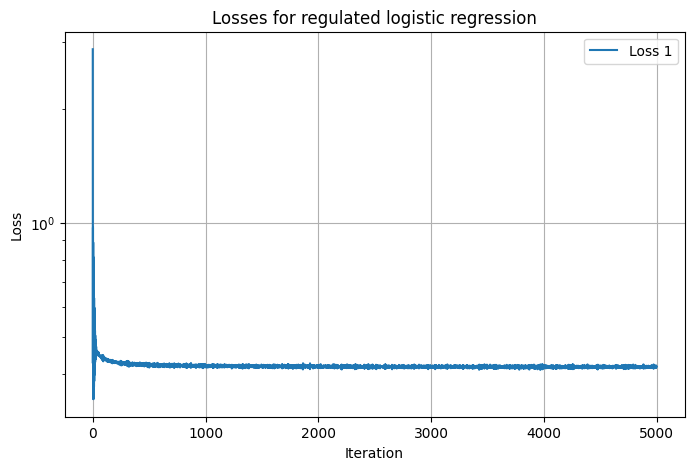

In [6]:
plot_losses([losses], title="Losses for regulated logistic regression")

## Evaluate the model


Accuracy:  0.7897206942264616
Precision:  0.25538766410701014
Recall:  0.6989830508474576
F1 Score:  0.37409288824383163


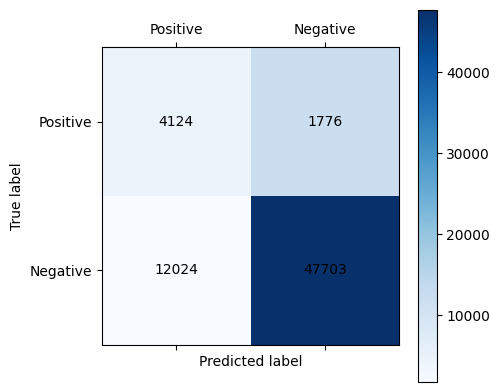

In [7]:
evaluate_model(model, x_test_norm, y_test)

## Generate predictions and create submission

In [8]:
online_test_preds = model.predict(x_online_test_norm)
create_csv_submission(
    online_test_ids, online_test_preds, "predictions/synapse-logreg-filtered-balanced-final.csv"
)